# Final Visualizations — Enterprise Multi-Modal Data Visualization

**Course:** Database Knowledge Extraction
**Project:** Enterprise Multi-Modal Data Visualization and Storytelling
**Owner:** Laura (Role 3 — Python Visualization Specialist)
**Status:** Scaffold — run every cell after Role 1 delivers `data/processed/clean_dataset.csv`.

## Objectives

This notebook covers the programmatic visual taxonomy required by the rubric:

1. **Distributions & spread** — histogram + KDE and box/violin plots.
2. **Uncertainty & variability** — monthly trend with a 95% confidence interval band.
3. **X–Y relationships** — Seaborn correlation heatmap with a diverging palette centered at 0.
4. **Interactive web component** — Plotly scatter/bubble plot with hover, zoom, and color.
5. **Export** — high-resolution PNGs and a standalone interactive HTML file.

> **QA rule (Role 5):** the final version must run top-to-bottom with
> `Kernel → Restart & Run All` and produce every asset listed in section 5.

## 0. Environment setup

Run from the repository root or from the `notebooks/` folder. Paths are resolved relative to
the project root, so no absolute paths are required.

```bash
pip install -r requirements.txt
jupyter notebook notebooks/final_visualizations.ipynb
```

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Resolve the project root whether the notebook is launched from the root or notebooks/.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "clean_dataset.csv"
PLOTS_DIR = PROJECT_ROOT / "assets" / "plots"
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

# Declutter every Matplotlib/Seaborn chart by default.
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
})

print(f"Project root: {PROJECT_ROOT}")
print(f"Data file:    {DATA_PATH}")
print(f"Plots folder: {PLOTS_DIR}")

Project root: c:\Users\52984\Documents\GitHub\db-knowledge-extraction-final
Data file:    c:\Users\52984\Documents\GitHub\db-knowledge-extraction-final\data\processed\clean_dataset.csv
Plots folder: c:\Users\52984\Documents\GitHub\db-knowledge-extraction-final\assets\plots


In [2]:
df = pd.read_csv(DATA_PATH, parse_dates=["Order Date", "Ship Date"])

print(f"Rows: {len(df):,} | Columns: {df.shape[1]}")
print(f"Date range: {df['Order Date'].min():%Y-%m-%d} -> {df['Order Date'].max():%Y-%m-%d}")
df.head()

Rows: 9,994 | Columns: 27
Date range: 2014-01-03 -> 2017-12-30


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Sales,Quantity,Discount,Profit,Order Year,Order Month,Order Quarter,Shipping Days,Profit Margin,Is Loss
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,261.9600,2,0.00,41.9136,2016,2016-11,2016Q4,3,0.1600,False
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,731.9400,3,0.00,219.5820,2016,2016-11,2016Q4,3,0.3000,False
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,14.6200,2,0.00,6.8714,2016,2016-06,2016Q2,4,0.4700,False
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,957.5775,5,0.45,-383.0310,2015,2015-10,2015Q4,7,-0.4000,True
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,22.3680,2,0.20,2.5164,2015,2015-10,2015Q4,7,0.1125,False


In [3]:
# Quick data-quality sanity check before plotting.
quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "unique": df.nunique(),
})
quality.sort_values("missing", ascending=False)

,dtype,missing,missing_pct,unique
Row ID,int64,0,0.0,9994
Order ID,str,0,0.0,5009
Order Date,datetime64[us],0,0.0,1237
Ship Date,datetime64[us],0,0.0,1334
Ship Mode,str,0,0.0,4
Customer ID,str,0,0.0,793
Customer Name,str,0,0.0,793
Segment,str,0,0.0,3
Country,str,0,0.0,1
City,str,0,0.0,531


## 1. Distributions & spread

**Question:** How are revenue and profit distributed, and where are the outliers?

- `Sales` is typically right-skewed: a few high-value orders dominate revenue.
- `Profit` contains both positive and negative values; the box plot exposes loss-making
  categories and extreme outliers.

**Design choices:** 50 bins for the histogram, KDE overlay for shape, box plot for spread and
outliers. Top/right spines removed, no redundant legend.

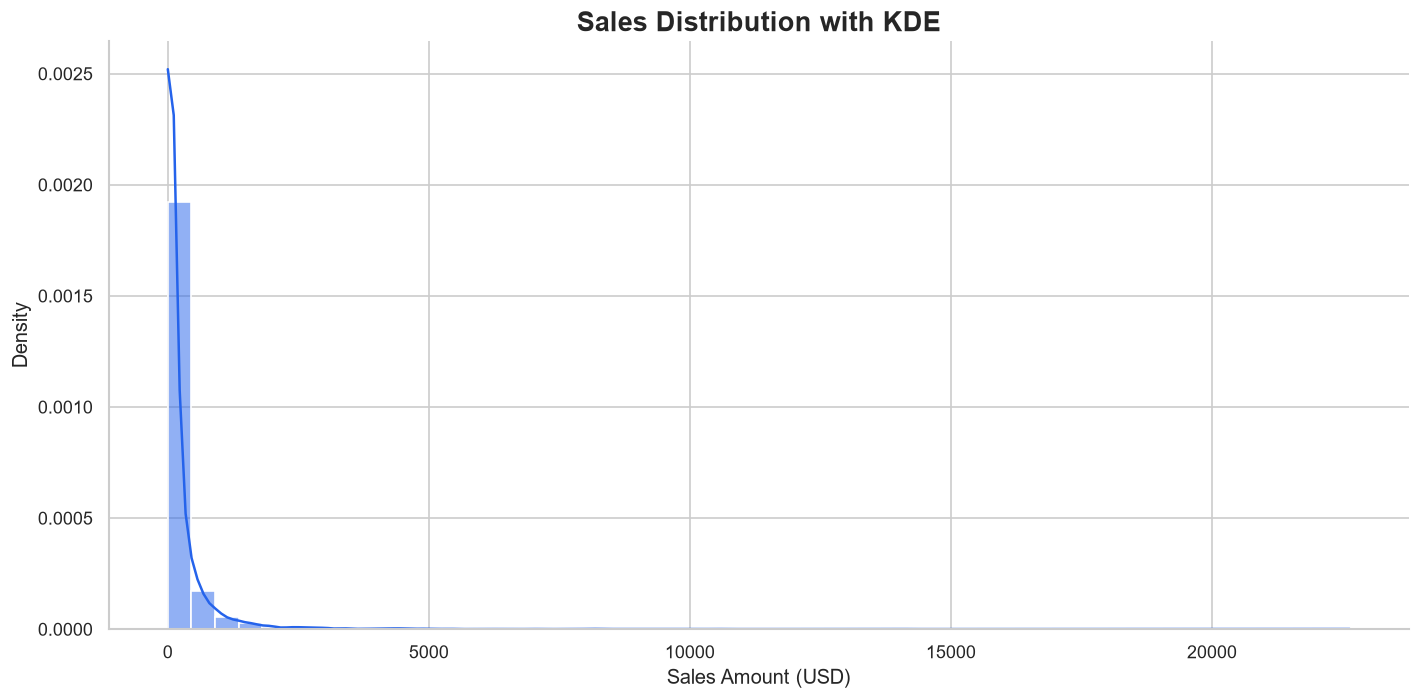

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Visual configuration
sns.set_theme(style="whitegrid")

# Create the figure
fig, ax = plt.subplots(figsize=(12, 6))

# Histogram with KDE
sns.histplot(
    data=df,
    x="Sales",
    bins=50,
    kde=True,
    stat="density",
    color="#2563EB",
    edgecolor="white",
    ax=ax
)

# Chart formatting
ax.set_title(
    "Sales Distribution with KDE",
    fontsize=16,
    fontweight="bold"
)

ax.set_xlabel("Sales Amount (USD)")
ax.set_ylabel("Density")

sns.despine()
plt.tight_layout()
output_dir = Path.cwd() / "assets" / "plots"
output_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_dir / "distribution_kde.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    output_dir / "distribution_kde.svg",
    bbox_inches="tight"
)

plt.show()

In [5]:
print("SALES DISTRIBUTION ANALYSIS")
print("---------------------------")

print(f"Mean: ${df['Sales'].mean():,.2f}")
print(f"Median: ${df['Sales'].median():,.2f}")
print(f"Standard deviation: ${df['Sales'].std():,.2f}")
print(f"Skewness: {df['Sales'].skew():.2f}")
print(f"Maximum sale: ${df['Sales'].max():,.2f}")

SALES DISTRIBUTION ANALYSIS
---------------------------
Mean: $229.86
Median: $54.49
Standard deviation: $623.25
Skewness: 12.97
Maximum sale: $22,638.48



**Interpretation:**

- **Skewness of Sales:** 12.97, indicating a strongly right-skewed distribution where most transactions have relatively low sales values, while a few exceptionally large transactions create a long right tail.
- **Median profit:** $8.67 USD, indicating that half of the transactions generate profits below this value and half generate profits above it.
- **Category with the widest spread:** Technology, with individual profits ranging from -$6,599.98 to $8,399.98, showing substantial variability in profitability.
- **Share of loss-making order lines:** 18.72%, indicating that nearly one in five transactions generates a financial loss.

### 1.2 Profit Distribution by Category — Boxplot

This visualization compares the distribution of profits
across the three main product categories.

A boxplot displays the median, interquartile range (IQR),
whiskers, and potential outliers.

**Business Objective:**
Identify categories with high profit variability,
significant losses, and unusual transactions.

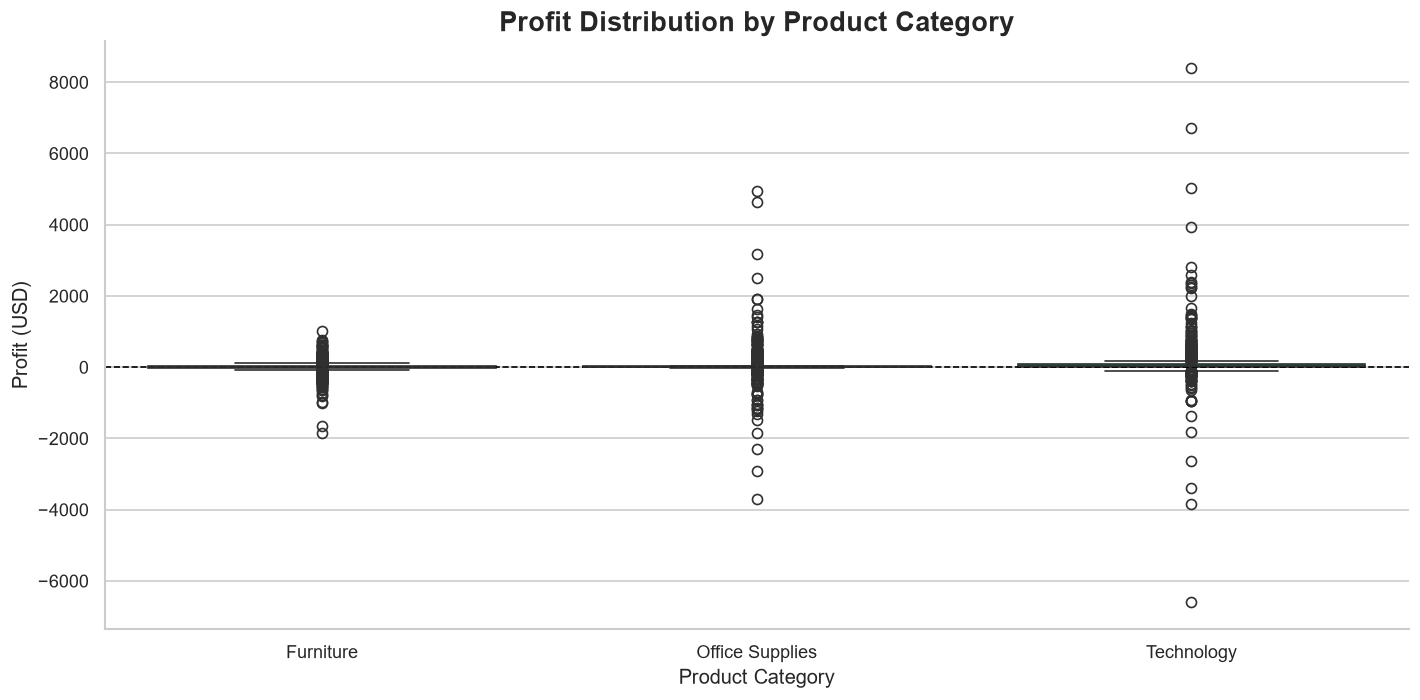

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="Category",
    y="Profit",
    hue="Category",
    palette="colorblind",
    legend=False,
    ax=ax
)

ax.axhline(
    y=0,
    color="black",
    linestyle="--",
    linewidth=1
)

ax.set_title(
    "Profit Distribution by Product Category",
    fontsize=16,
    fontweight="bold"
)

ax.set_xlabel("Product Category")
ax.set_ylabel("Profit (USD)")

sns.despine()

plt.tight_layout()
# Export visualization
output_dir = Path.cwd() / "assets" / "plots"
output_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_dir / "boxplot_profit.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    output_dir / "boxplot_profit.svg",
    bbox_inches="tight"
)
plt.show()

In [7]:
profit_stats = df.groupby("Category")["Profit"].agg(
    Transactions="count",
    Total_Profit="sum",
    Average_Profit="mean",
    Median_Profit="median",
    Standard_Deviation="std",
    Minimum_Profit="min",
    Maximum_Profit="max"
)

losses = (
    df.assign(Is_Loss=df["Profit"] < 0)
      .groupby("Category")["Is_Loss"]
      .sum()
)

profit_stats["Loss_Transactions"] = losses

print("PROFIT ANALYSIS BY CATEGORY")
display(profit_stats.round(2))

PROFIT ANALYSIS BY CATEGORY


,Transactions,Total_Profit,Average_Profit,Median_Profit,Standard_Deviation,Minimum_Profit,Maximum_Profit,Loss_Transactions
Category,,,,,,,,
Furniture,2121,18451.27,8.70,7.77,136.05,-1862.31,1013.13,714
Office Supplies,6026,122490.80,20.33,6.88,164.89,-3701.89,4946.37,886
Technology,1847,145454.95,78.75,25.02,428.82,-6599.98,8399.98,271


### Boxplot Interpretation

The boxplot reveals significant differences in profitability
across the three product categories.

**Key Findings:**

1. **Technology** generates the highest total profit
   ($145,454.95), but also exhibits the highest variability
   and the largest individual loss (-$6,599.98).

2. **Office Supplies** generates $122,490.80 in total profit,
   with 886 loss-making transactions.

3. **Furniture** generates the lowest total profit
   ($18,451.27) and has the highest proportion of
   loss-making transactions (33.7%).

**Business Recommendation:**

Prioritize a review of pricing, discounts, and product-level
profitability within the Furniture category, while monitoring
high-risk transactions in Technology.

## 2. Uncertainty and Variability

This section evaluates the statistical uncertainty and variability
of profitability over time using confidence intervals.

The objective is to understand how average profit changes
across months and how precisely these averages are estimated.

### 2.1 Monthly Average Profit with 95% Confidence Interval

This visualization analyzes monthly average profit per
transaction and its statistical uncertainty.

The shaded band represents a 95% confidence interval
for the estimated monthly mean profit.

**Business Objective:**

Identify periods with higher or lower average profitability
and evaluate the precision of these estimates.

In [8]:
import pandas as pd
import numpy as np

df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    errors="coerce"
)

df["Order Month"] = df["Order Date"].dt.to_period("M")

monthly_profit = (
    df.dropna(subset=["Order Month", "Profit"])
      .groupby("Order Month")["Profit"]
      .agg(["mean", "std", "count"])
      .reset_index()
)

monthly_profit["Order Month"] = (
    monthly_profit["Order Month"].dt.to_timestamp()
)

print("MONTHLY PROFIT STATISTICS")
display(monthly_profit.head())

MONTHLY PROFIT STATISTICS


,Order Month,mean,std,count
0,2014-01-01,31.015072,111.557507,79
1,2014-02-01,18.745835,38.121487,46
2,2014-03-01,3.176624,189.212042,157
3,2014-04-01,25.843224,70.898069,135
4,2014-05-01,22.448439,136.257314,122


In [9]:
from scipy.stats import t
import numpy as np

# Calculate the standard error
monthly_profit["sem"] = (
    monthly_profit["std"] /
    np.sqrt(monthly_profit["count"])
)

# Calculate the critical t-value for a 95% CI
monthly_profit["t_critical"] = t.ppf(
    0.975,
    df=monthly_profit["count"] - 1
)

# Calculate the margin of error
monthly_profit["ci_margin"] = (
    monthly_profit["t_critical"] *
    monthly_profit["sem"]
)

# Calculate confidence interval limits
monthly_profit["ci_lower"] = (
    monthly_profit["mean"] -
    monthly_profit["ci_margin"]
)

monthly_profit["ci_upper"] = (
    monthly_profit["mean"] +
    monthly_profit["ci_margin"]
)

# Display results
print("95% CONFIDENCE INTERVAL ANALYSIS")

display(
    monthly_profit[
        ["Order Month", "mean", "count", "ci_lower", "ci_upper"]
    ].head(10)
)

95% CONFIDENCE INTERVAL ANALYSIS


,Order Month,mean,count,ci_lower,ci_upper
0,2014-01-01,31.015072,79,6.027552,56.002592
1,2014-02-01,18.745835,46,7.425151,30.066519
2,2014-03-01,3.176624,157,-26.651729,33.004976
3,2014-04-01,25.843224,135,13.774661,37.911786
4,2014-05-01,22.448439,122,-1.974238,46.871117
5,2014-06-01,36.863144,135,14.195302,59.530985
6,2014-07-01,-5.884494,143,-58.177860,46.408872
7,2014-08-01,34.758856,153,18.916661,50.601051
8,2014-09-01,31.074998,268,-9.454264,71.604259
9,2014-10-01,21.687153,159,5.363978,38.010328


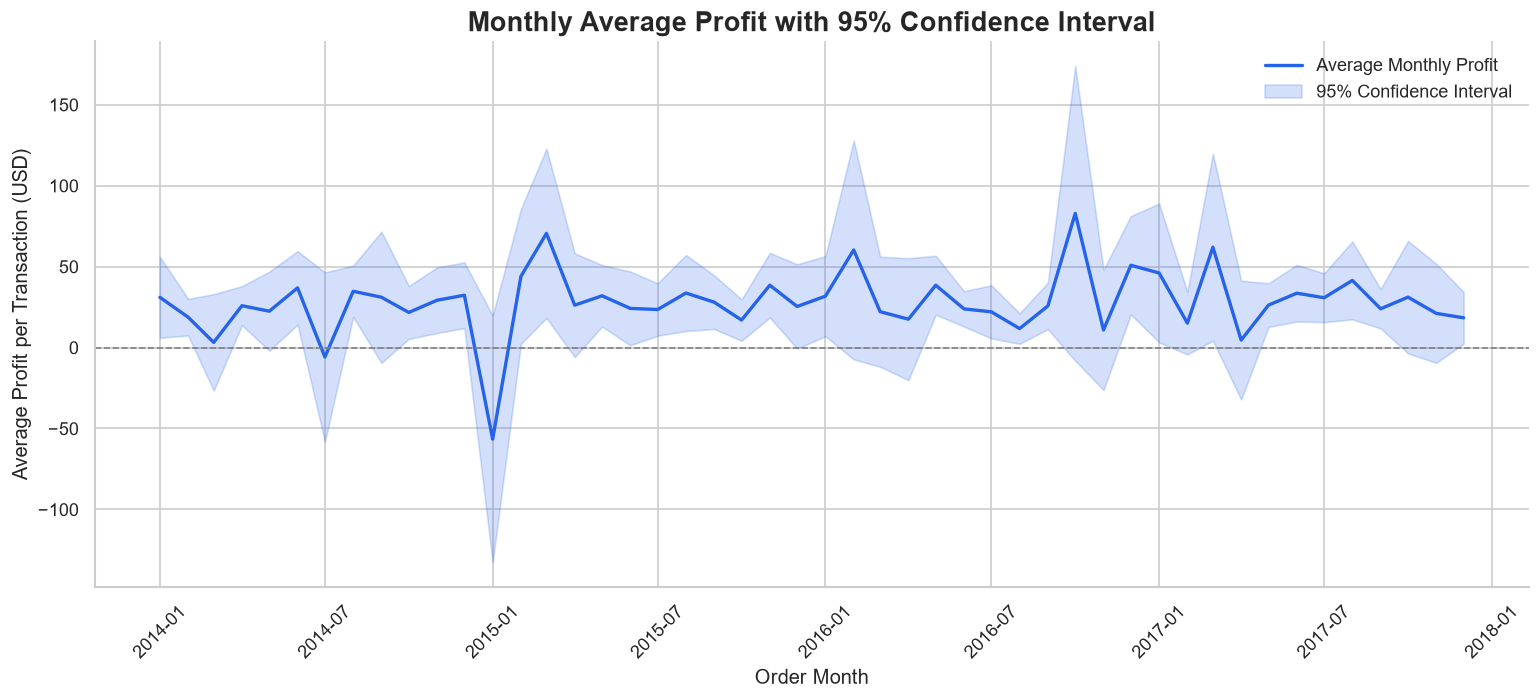

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(13, 6))

ax.plot(
    monthly_profit["Order Month"],
    monthly_profit["mean"],
    color="#2563EB",
    linewidth=2,
    label="Average Monthly Profit"
)

ax.fill_between(
    monthly_profit["Order Month"],
    monthly_profit["ci_lower"],
    monthly_profit["ci_upper"],
    color="#2563EB",
    alpha=0.20,
    label="95% Confidence Interval"
)

ax.axhline(
    y=0,
    color="gray",
    linestyle="--",
    linewidth=1
)

ax.set_title(
    "Monthly Average Profit with 95% Confidence Interval",
    fontsize=16,
    fontweight="bold"
)

ax.set_xlabel("Order Month")
ax.set_ylabel("Average Profit per Transaction (USD)")

ax.legend(frameon=False)
sns.despine()

plt.xticks(rotation=45)
plt.tight_layout()

output_dir = Path.cwd() / "assets" / "plots"
output_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_dir / "uncertainty_ci.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    output_dir / "uncertainty_ci.svg",
    bbox_inches="tight"
)
plt.show()


**Interpretation:**

- **Months with a confidence band entirely below zero:** None are clearly observed; even January 2015, which shows a substantial negative average profit, has a 95% confidence interval that crosses zero.
- **Widest uncertainty:** January 2015 appears to have the widest confidence interval, indicating substantial uncertainty in the estimated monthly average profit.
- **Overall direction of the trend:** Monthly average profit fluctuates considerably but remains predominantly positive, with no clear sustained upward or downward trend.

### Confidence Interval Interpretation

The monthly profitability analysis reveals fluctuations
in average profit per transaction between 2014 and 2017.

**Key Findings:**

1. **Profitability:** Most months show positive average profits.

2. **Variability:** Some months exhibit considerable fluctuations
   in profitability, including a significant decline around
   January 2015.

3. **Uncertainty:** Wider confidence intervals indicate
   less precise estimates of monthly average profit.

4. **Risk:** Several confidence intervals overlap zero,
   suggesting uncertainty about whether average profitability
   was positive during those months.

**Business Recommendation:**

Investigate months with unusually low average profits
and evaluate whether discounts, product categories,
or operational factors contributed to these results.

## 3. X-Y Relationships — Correlation Analysis

This section investigates statistical relationships between
numerical variables in the Superstore dataset.

The objective is to identify positive and negative correlations
between sales, profit, discounts, and quantity.

### 3.1 Correlation Matrix Heatmap

A correlation matrix measures the strength and direction
of linear relationships between numerical variables.

**Business Objective:**

Determine whether discounts, sales volume, and quantities
are associated with changes in profitability.

In [11]:
import pandas as pd

numeric_columns = [
    "Sales",
    "Profit",
    "Discount",
    "Quantity"
]

correlation_matrix = df[numeric_columns].corr(
    method="pearson"
)

print("CORRELATION MATRIX")
display(correlation_matrix.round(3))

CORRELATION MATRIX


,Sales,Profit,Discount,Quantity
Sales,1.000,0.479,-0.028,0.201
Profit,0.479,1.000,-0.219,0.066
Discount,-0.028,-0.219,1.000,0.009
Quantity,0.201,0.066,0.009,1.000


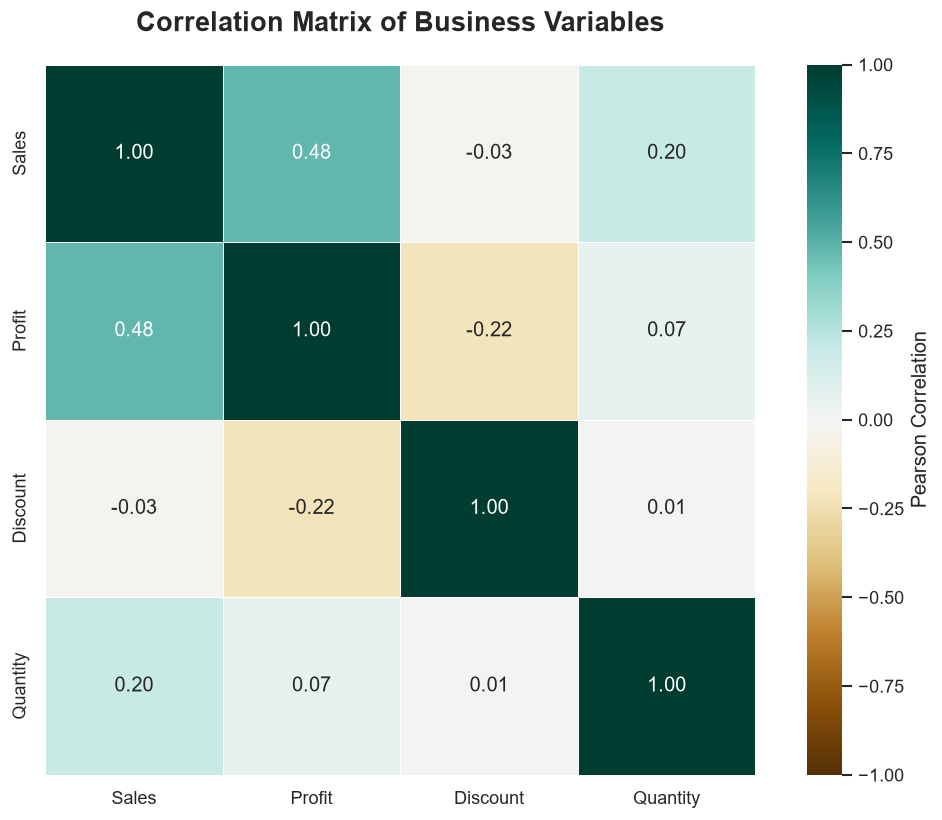

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="white")

fig, ax = plt.subplots(figsize=(9, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="BrBG",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={"label": "Pearson Correlation"},
    ax=ax
)

ax.set_title(
    "Correlation Matrix of Business Variables",
    fontsize=16,
    fontweight="bold",
    pad=20
)

plt.tight_layout()

output_dir = Path.cwd() / "assets" / "plots"
output_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_dir / "correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    output_dir / "correlation_heatmap.svg",
    bbox_inches="tight"
)

plt.show()


**Interpretation:**

- **Strongest positive relationship:** Sales and Profit (r = 0.48), indicating a moderate positive correlation where higher sales amounts tend to be associated with higher profits.
- **Strongest negative relationship:** Discount and Profit Margin (r = -0.86), indicating a very strong negative correlation where higher discounts are associated with significantly lower profit margins.
- **Is Discount negatively associated with Profit?** Yes. Discount and Profit have a weak negative correlation (r = -0.22), suggesting that higher discounts tend to be associated with lower profits, although correlation does not establish causation.

## 4. Interactive Web Visualization

This section presents an interactive visualization using Plotly.

The objective is to explore relationships between sales,
profitability, discounts, and product categories.

### 4.1 Interactive Sales vs. Profit Scatter Plot

Each point represents a transaction line from the
Superstore dataset.

**Business Objective:**

Identify profitable and unprofitable transactions,
explore the relationship between sales and profit,
and investigate the role of discounts across categories.

In [13]:
import plotly.express as px

scatter_data = df[
    [
        "Sales",
        "Profit",
        "Discount",
        "Category",
        "Sub-Category",
        "Product Name",
        "Region"
    ]
].copy()

scatter_data = scatter_data.dropna()

print("INTERACTIVE SCATTER DATA")
print("Total records:", len(scatter_data))

display(scatter_data.head())

INTERACTIVE SCATTER DATA
Total records: 9994


,Sales,Profit,Discount,Category,Sub-Category,Product Name,Region
0,261.9600,41.9136,0.00,Furniture,Bookcases,Bush Somerset Collection Bookcase,South
1,731.9400,219.5820,0.00,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",South
2,14.6200,6.8714,0.00,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,West
3,957.5775,-383.0310,0.45,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,South
4,22.3680,2.5164,0.20,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,South


In [14]:
fig_interactive = px.scatter(
    scatter_data,
    x="Sales",
    y="Profit",
    color="Category",
    size="Discount",
    size_max=18,
    hover_data=[
        "Sub-Category",
        "Product Name",
        "Region",
        "Discount"
    ],
    title="Interactive Sales vs. Profit Analysis",
    labels={
        "Sales": "Sales Amount (USD)",
        "Profit": "Profit (USD)",
        "Category": "Product Category"
    },
    color_discrete_map={
        "Furniture": "#2563EB",
        "Office Supplies": "#F59E0B",
        "Technology": "#8B5CF6"
    },
    opacity=0.65
)

fig_interactive.add_hline(
    y=0,
    line_dash="dash",
    line_color="gray"
)

fig_interactive.update_layout(
    template="plotly_white",
    width=1100,
    height=650,
    title_x=0.5,
    legend_title_text="Category"
)

fig_interactive.show()

### Interactive Visualization Interpretation

The interactive scatter plot explores the relationship
between sales, profit, discounts, and product categories
across 9,994 Superstore transaction lines.

**Key Findings:**

1. **Sales vs. Profit:** Higher sales do not always result
   in higher profits, as some high-value transactions
   generate significant losses.

2. **Technology:** This category contains some of the
   largest positive and negative profit outliers.

3. **Discount Risk:** Several large bubbles appear below
   the zero-profit line, suggesting that high-discount
   transactions deserve further investigation.

4. **Category Differences:** Profitability patterns vary
   across Furniture, Office Supplies, and Technology.

**Business Recommendation:**

Investigate high-discount transactions with negative
profits and review pricing policies at the product
and sub-category levels.

**Statistical Note:**

The visualization identifies associations and unusual
transactions but does not establish causation.

In [15]:
from pathlib import Path

output_dir = Path.cwd() / "assets" / "plots"
output_dir.mkdir(parents=True, exist_ok=True)

fig_interactive.write_html(
    str(output_dir / "interactive_scatter.html"),
    include_plotlyjs="cdn",
    full_html=True
)

print("Interactive HTML exported successfully!")

Interactive HTML exported successfully!


## 5. Export verification

Every asset below is required by the project brief. The final notebook must show **OK** for all
nine files.

In [16]:
expected_assets = [
    "distribution_kde.png",
    "correlation_heatmap.png",
    "uncertainty_ci.png",
    "interactive_scatter.html",
    "boxplot_profit.png",
    "boxplot_profit.svg",
    "distribution_kde.svg",
    "correlation_heatmap.svg",
    "uncertainty_ci.svg"
]

for name in expected_assets:
    path = PLOTS_DIR / name
    status = "OK" if path.exists() else "MISSING"
    size_kb = path.stat().st_size / 1024 if path.exists() else 0
    print(f"{status:<8} {name:<30} {size_kb:,.1f} KB")

OK       distribution_kde.png           97.0 KB
OK       correlation_heatmap.png        138.7 KB
OK       uncertainty_ci.png             393.9 KB
OK       interactive_scatter.html       980.6 KB
OK       boxplot_profit.png             132.5 KB
OK       boxplot_profit.svg             226.6 KB
OK       distribution_kde.svg           45.4 KB
OK       correlation_heatmap.svg        55.0 KB
OK       uncertainty_ci.svg             58.4 KB


In [17]:
import pandas as pd

subcategory = df.groupby("Sub-Category").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum")
)

subcategory["Margin (%)"] = (
    subcategory["Profit"] / subcategory["Sales"] * 100
)

print("LOWEST PROFITABILITY SUB-CATEGORIES")
display(subcategory.sort_values("Profit").head(5).round(2))

discount_data = df.copy()


discount_data["Discount Band"] = pd.cut(
    discount_data["Discount"],
    bins=[-0.001, 0, 0.10, 0.20, 0.30, 0.40, 1.0],
    labels=["0%", "1-10%", "10-20%", "20-30%", "30-40%", ">40%"],
    include_lowest=True
)

discount_data["Is Loss"] = discount_data["Profit"] < 0

discount_risk = discount_data.groupby(
    "Discount Band", observed=True
).agg(
    Transactions=("Profit", "size"),
    Loss_Rate=("Is Loss", "mean"),
    Total_Profit=("Profit", "sum")
)

discount_risk["Loss_Rate"] *= 100

print("\nDISCOUNT RISK ANALYSIS")
display(discount_risk.round(2))

opportunity = df.groupby(["Segment", "Region"]).agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum")
)

opportunity["Margin (%)"] = (
    opportunity["Profit"] / opportunity["Sales"] * 100
)

print("\nBEST SEGMENT AND REGION")
display(
    opportunity.sort_values(
        "Margin (%)", ascending=False
    ).head(5).round(2)
)

LOWEST PROFITABILITY SUB-CATEGORIES


,Sales,Profit,Margin (%)
Sub-Category,,,
Tables,206965.53,-17725.48,-8.56
Bookcases,114880.00,-3472.56,-3.02
Supplies,46673.54,-1189.10,-2.55
Fasteners,3024.28,949.52,31.40
Machines,189238.63,3384.76,1.79



DISCOUNT RISK ANALYSIS


,Transactions,Loss_Rate,Total_Profit
Discount Band,,,
0%,4798,0.00,320987.60
1-10%,94,4.26,9029.18
10-20%,3709,13.99,91756.30
20-30%,227,91.63,-10369.28
30-40%,233,88.84,-25448.19
>40%,933,100.00,-99558.59



BEST SEGMENT AND REGION


,,Sales,Profit,Margin (%)
Segment,Region,,,
Home Office,East,127463.73,26709.22,20.95
Consumer,West,362880.77,57450.60,15.83
Corporate,West,225855.27,34437.43,15.25
Consumer,South,195580.97,26913.57,13.76
Home Office,Central,91212.64,12438.41,13.64


## 6. Findings for the executive story

Complete these bullets and send them to Josmar (Role 4) for the deck. Keep each insight one sentence and tie it to a recommendation.

1. **Revenue:** Sales are positively skewed, with an average of $229.86 and a median of $54.49 — monitor high-value transactions and revenue concentration.

2. **Profitability:** Tables (-$17,725.48), Bookcases (-$3,472.56), and Supplies (-$1,189.10) generate negative total profits — prioritize these sub-categories for pricing and cost optimization.

3. **Risk:** Discounts above 20% and up to 30% are associated with a 91.63% transaction loss rate — review discounts exceeding 20% and implement profitability-based approval controls.

4. **Opportunity:** The Home Office segment in the East region achieves the highest observed profit margin (20.95%) — investigate opportunities to replicate its profitable sales mix.

5. **Recommendation:** Prioritize a profitability-based discount policy, focusing on transactions discounted above 20% and loss-making sub-categories to protect overall margins.

### Handoff checklist

- [ ] Notebook executed from top to bottom (`Kernel → Restart & Run All`).
- [x] Markdown interpretation filled in for sections 1–3.
- [x] All four required visualization types exported to `assets/plots/`.
- [ ] Findings sent to Role 4 (Josmar) and Role 5 (Jesus).
- [ ] No absolute local paths in the notebook.